In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

In [2]:
data_dir = Path("data")

year_files = {
    2004: data_dir / "2004.csv.bz2",
    2005: data_dir / "2005.csv.bz2",
    2006: data_dir / "2006.csv.bz2",
    2007: data_dir / "2007.csv.bz2",
    2008: data_dir / "2008.csv.bz2",
}

for year, path in year_files.items():
    print(year, path.exists(), path)

2004 True data/2004.csv.bz2
2005 True data/2005.csv.bz2
2006 True data/2006.csv.bz2
2007 True data/2007.csv.bz2
2008 True data/2008.csv.bz2


In [3]:
use_cols = [
    "Year", "Month", "DayofMonth", "DayOfWeek",
    "DepTime", "CRSDepTime", "ArrTime", "CRSArrTime",
    "UniqueCarrier", "TailNum",
    "ArrDelay", "DepDelay",
    "Origin", "Dest", "Distance",
    "TaxiIn", "TaxiOut",
    "Cancelled", "Diverted"
]

frames = []

for year, path in year_files.items():
    df_year = pd.read_csv(path, usecols=use_cols, compression="bz2")
    frames.append(df_year)
    print(year, df_year.shape)

flights_raw = pd.concat(frames, ignore_index=True)
print("Combined shape:", flights_raw.shape)
flights_raw.head()

2004 (7129270, 19)
2005 (7140596, 19)
2006 (7141922, 19)
2007 (7453215, 19)
2008 (2389217, 19)
Combined shape: (31254220, 19)


,Year,Month,DayofMonth,DayOfWeek,DepTime,CRSDepTime,ArrTime,CRSArrTime,UniqueCarrier,TailNum,ArrDelay,DepDelay,Origin,Dest,Distance,TaxiIn,TaxiOut,Cancelled,Diverted
0,2004,1,12,1,623.0,630,901.0,915,UA,N805UA,-14.0,-7.0,ORD,CLT,599,7.0,11.0,0,0
1,2004,1,13,2,621.0,630,911.0,915,UA,N851UA,-4.0,-9.0,ORD,CLT,599,16.0,16.0,0,0
2,2004,1,14,3,633.0,630,920.0,915,UA,N436UA,5.0,3.0,ORD,CLT,599,4.0,15.0,0,0
3,2004,1,15,4,627.0,630,859.0,915,UA,N828UA,-16.0,-3.0,ORD,CLT,599,4.0,10.0,0,0
4,2004,1,16,5,635.0,630,918.0,915,UA,N831UA,3.0,5.0,ORD,CLT,599,3.0,13.0,0,0


In [4]:
flights_a = flights_raw.copy()

print(flights_a.shape)
flights_a[["ArrDelay", "DepDelay", "Cancelled", "Diverted"]].isna().sum()

(31254220, 19)


ArrDelay     675442
DepDelay     608611
Cancelled         0
Diverted          0
dtype: int64

In [5]:
# For part 2(a), cancelled flights do not have meaningful realized delays.
# We also drop rows where both main delay measures are missing.

flights_a = flights_a[flights_a["Cancelled"] == 0].copy()
flights_a = flights_a.dropna(subset=["ArrDelay", "DepDelay", "CRSDepTime", "DayOfWeek", "Year"])

print(flights_a.shape)

(30578778, 19)


In [6]:
def hhmm_to_hour(x):
    if pd.isna(x):
        return np.nan
    x = int(x)
    hour = x // 100
    minute = x % 100
    if hour < 0 or hour > 23 or minute < 0 or minute > 59:
        return np.nan
    return hour

flights_a["sched_dep_hour"] = flights_a["CRSDepTime"].apply(hhmm_to_hour)

# Day labels for readability
day_map = {
    1: "Mon",
    2: "Tue",
    3: "Wed",
    4: "Thu",
    5: "Fri",
    6: "Sat",
    7: "Sun"
}

flights_a["day_name"] = flights_a["DayOfWeek"].map(day_map)

print(flights_a[["CRSDepTime", "sched_dep_hour", "DayOfWeek", "day_name"]].head())
print(flights_a["sched_dep_hour"].isna().sum())

   CRSDepTime  sched_dep_hour  DayOfWeek day_name
0         630               6          1      Mon
1         630               6          2      Tue
2         630               6          3      Wed
3         630               6          4      Thu
4         630               6          5      Fri
0


In [7]:
flights_a = flights_a.dropna(subset=["sched_dep_hour", "day_name"]).copy()

print(flights_a.shape)

delay_summary_hour = (
    flights_a
    .groupby(["Year", "sched_dep_hour"], as_index=False)
    .agg(
        mean_arr_delay=("ArrDelay", "mean"),
        mean_dep_delay=("DepDelay", "mean"),
        n_flights=("ArrDelay", "size")
    )
)

delay_summary_day = (
    flights_a
    .groupby(["Year", "day_name", "DayOfWeek"], as_index=False)
    .agg(
        mean_arr_delay=("ArrDelay", "mean"),
        mean_dep_delay=("DepDelay", "mean"),
        n_flights=("ArrDelay", "size")
    )
    .sort_values(["Year", "DayOfWeek"])
)

print(delay_summary_hour.head())
print(delay_summary_day.head(10))

(30578778, 21)
   Year  sched_dep_hour  mean_arr_delay  mean_dep_delay  n_flights
0  2004               0        1.618266        4.133540       9690
1  2004               1        0.641845        2.647407       5573
2  2004               2       -3.062302        2.070750        947
3  2004               3       -1.544118        7.073529         68
4  2004               4       -7.259259       -6.000000         27
    Year day_name  DayOfWeek  mean_arr_delay  mean_dep_delay  n_flights
1   2004      Mon          1        7.797879        8.957124    1022398
5   2004      Tue          2        5.510747        6.567052    1013439
6   2004      Wed          3        6.823174        7.410902    1014993
4   2004      Thu          4        7.938058        8.761728    1038525
0   2004      Fri          5        7.978558        8.945335    1040966
2   2004      Sat          6        2.649383        5.780889     887333
3   2004      Sun          7        6.281599        8.291695     970075
8   200

In [8]:
best_hour_each_year = (
    delay_summary_hour
    .sort_values(["Year", "mean_arr_delay", "mean_dep_delay", "sched_dep_hour"])
    .groupby("Year", as_index=False)
    .first()
)

best_hour_each_year

,Year,sched_dep_hour,mean_arr_delay,mean_dep_delay,n_flights
0,2004,4,-7.259259,-6.000000,27
1,2005,5,-1.415424,1.244276,58610
2,2006,5,-0.350445,0.985176,41082
3,2007,3,0.726154,11.298462,325
4,2008,4,-0.208054,3.741611,298


In [9]:
best_day_each_year = (
    delay_summary_day
    .sort_values(["Year", "mean_arr_delay", "mean_dep_delay", "DayOfWeek"])
    .groupby("Year", as_index=False)
    .first()
)

best_day_each_year

,Year,day_name,DayOfWeek,mean_arr_delay,mean_dep_delay,n_flights
0,2004,Sat,6,2.649383,5.780889,887333
1,2005,Sat,6,3.301072,6.522569,900609
2,2006,Sat,6,5.169126,8.264994,886411
3,2007,Sat,6,5.846600,8.965287,915626
4,2008,Sat,6,7.509435,9.964717,281129


In [10]:
print("Best scheduled departure hour by year:")
print(best_hour_each_year.to_string(index=False))

print("\nBest day of week by year:")
print(best_day_each_year[["Year", "day_name", "DayOfWeek", "mean_arr_delay", "mean_dep_delay", "n_flights"]].to_string(index=False))

Best scheduled departure hour by year:
 Year  sched_dep_hour  mean_arr_delay  mean_dep_delay  n_flights
 2004               4       -7.259259       -6.000000         27
 2005               5       -1.415424        1.244276      58610
 2006               5       -0.350445        0.985176      41082
 2007               3        0.726154       11.298462        325
 2008               4       -0.208054        3.741611        298

Best day of week by year:
 Year day_name  DayOfWeek  mean_arr_delay  mean_dep_delay  n_flights
 2004      Sat          6        2.649383        5.780889     887333
 2005      Sat          6        3.301072        6.522569     900609
 2006      Sat          6        5.169126        8.264994     886411
 2007      Sat          6        5.846600        8.965287     915626
 2008      Sat          6        7.509435        9.964717     281129


In [11]:
hour_threshold = 10000

delay_summary_hour_filtered = delay_summary_hour[delay_summary_hour["n_flights"] >= hour_threshold].copy()

best_hour_each_year_filtered = (
    delay_summary_hour_filtered
    .sort_values(["Year", "mean_arr_delay", "mean_dep_delay", "sched_dep_hour"])
    .groupby("Year", as_index=False)
    .first()
)

print("Best scheduled departure hour by year (filtered):")
print(best_hour_each_year_filtered.to_string(index=False))

Best scheduled departure hour by year (filtered):
 Year  sched_dep_hour  mean_arr_delay  mean_dep_delay  n_flights
 2004               5       -1.312918        1.886672      53570
 2005               5       -1.415424        1.244276      58610
 2006               5       -0.350445        0.985176      41082
 2007               6        1.414156        2.279191     510926
 2008               5        2.496442        2.010842      14757


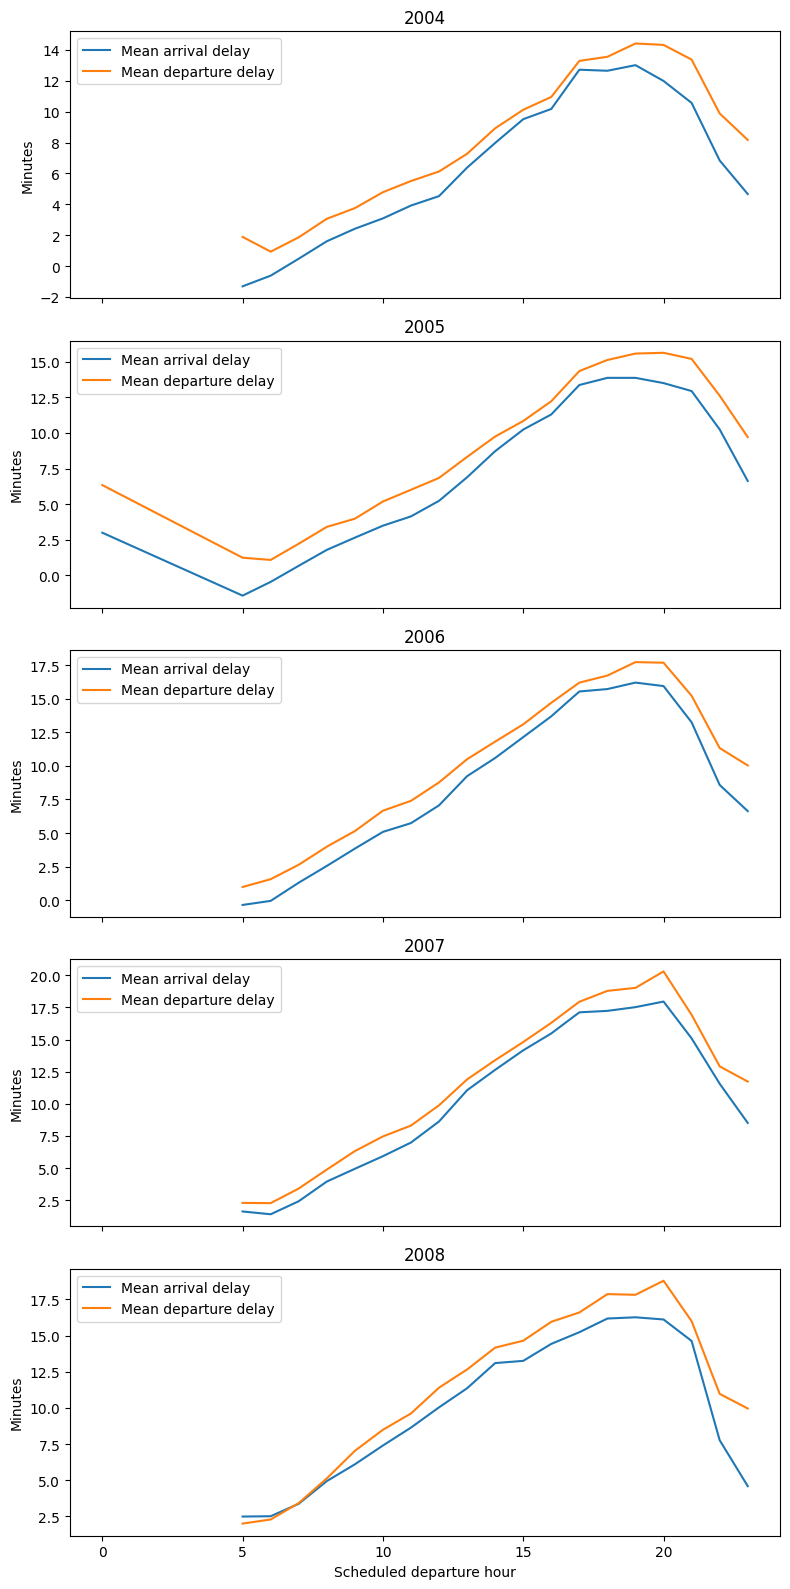

In [12]:
years = sorted(delay_summary_hour_filtered["Year"].unique())

fig, axes = plt.subplots(len(years), 1, figsize=(8, 16), sharex=True)

for ax, year in zip(axes, years):
    temp = delay_summary_hour_filtered[delay_summary_hour_filtered["Year"] == year]
    ax.plot(temp["sched_dep_hour"], temp["mean_arr_delay"], label="Mean arrival delay")
    ax.plot(temp["sched_dep_hour"], temp["mean_dep_delay"], label="Mean departure delay")
    ax.set_title(f"{year}")
    ax.set_ylabel("Minutes")
    ax.legend()

axes[-1].set_xlabel("Scheduled departure hour")
plt.tight_layout()
plt.savefig("part2_python_2a_hourly_delay.png", dpi=300, bbox_inches="tight")
plt.show()

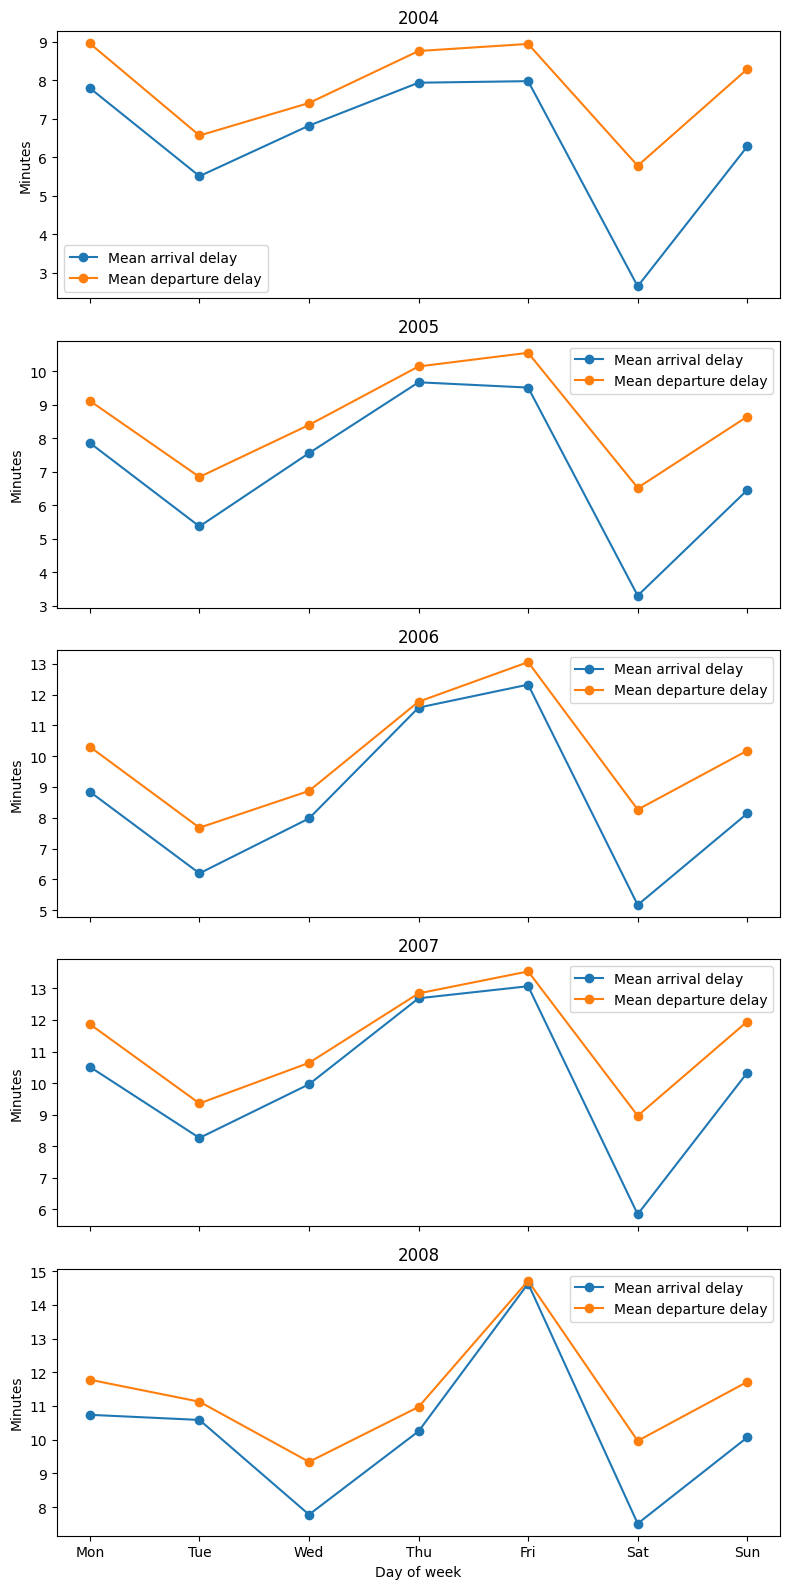

In [13]:
day_order = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

fig, axes = plt.subplots(len(years), 1, figsize=(8, 16), sharex=True)

for ax, year in zip(axes, years):
    temp = delay_summary_day[delay_summary_day["Year"] == year].copy()
    temp["day_name"] = pd.Categorical(temp["day_name"], categories=day_order, ordered=True)
    temp = temp.sort_values("day_name")

    ax.plot(temp["day_name"], temp["mean_arr_delay"], marker="o", label="Mean arrival delay")
    ax.plot(temp["day_name"], temp["mean_dep_delay"], marker="o", label="Mean departure delay")
    ax.set_title(f"{year}")
    ax.set_ylabel("Minutes")
    ax.legend()

axes[-1].set_xlabel("Day of week")
plt.tight_layout()
plt.savefig("part2_python_2a_day_delay.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
delay_summary_hour.to_csv("data/delay_summary_hour_2004_2008.csv", index=False)
delay_summary_day.to_csv("data/delay_summary_day_2004_2008.csv", index=False)
best_hour_each_year_filtered.to_csv("data/best_hour_each_year_filtered.csv", index=False)
best_day_each_year.to_csv("data/best_day_each_year.csv", index=False)

In [18]:
plane_data = pd.read_csv("data/plane-data.csv")
print(plane_data.shape)
print(plane_data.columns.tolist())
print(plane_data["year"].head(20))
print(plane_data["year"].notna().sum())

(5029, 9)
['tailnum', 'type', 'manufacturer', 'issue_date', 'model', 'status', 'aircraft_type', 'engine_type', 'year']
0    NaN
1    NaN
2    NaN
3    NaN
4    NaN
5    NaN
6    NaN
7    NaN
8    NaN
9    NaN
10   NaN
11   NaN
12   NaN
13   NaN
14   NaN
15   NaN
16   NaN
17   NaN
18   NaN
19   NaN
Name: year, dtype: float64
4335


In [19]:
plane_data.columns = [col.strip() for col in plane_data.columns]
plane_data["tailnum"] = plane_data["tailnum"].astype(str).str.strip().str.upper()
plane_data["year"] = pd.to_numeric(plane_data["year"], errors="coerce")

print("Rows with valid plane year:", plane_data["year"].notna().sum())
print("Unique tail numbers with valid plane year:", plane_data.loc[plane_data["year"].notna(), "tailnum"].nunique())

Rows with valid plane year: 4335
Unique tail numbers with valid plane year: 4335


In [20]:
plane_data_small = plane_data[["tailnum", "year"]].copy()
plane_data_small = plane_data_small.rename(columns={"tailnum": "TailNum", "year": "PlaneYear"})

flights_b = flights_raw[[
    "Year", "TailNum", "ArrDelay", "DepDelay", "Cancelled", "Diverted"
]].copy()

flights_b["TailNum"] = flights_b["TailNum"].astype(str).str.strip().str.upper()
flights_b = flights_b[flights_b["Cancelled"] == 0].copy()
flights_b = flights_b.dropna(subset=["TailNum", "ArrDelay", "DepDelay", "Year"])

merged_b = flights_b.merge(plane_data_small, on="TailNum", how="left")
merged_b["PlaneYear"] = pd.to_numeric(merged_b["PlaneYear"], errors="coerce")

print("Flights before plane-year filter:", merged_b.shape)
print("Flights with valid plane year:", merged_b["PlaneYear"].notna().sum())
print("Match rate:", merged_b["PlaneYear"].notna().mean())

Flights before plane-year filter: (30578776, 7)
Flights with valid plane year: 22959362
Match rate: 0.7508267171975752


In [22]:
plane_data = pd.read_csv("data/plane-data.csv")
plane_data.columns = [col.strip() for col in plane_data.columns]
plane_data["tailnum"] = plane_data["tailnum"].astype(str).str.strip().str.upper()
plane_data["year"] = pd.to_numeric(plane_data["year"], errors="coerce")

plane_data_small = plane_data[["tailnum", "year"]].copy()
plane_data_small = plane_data_small.rename(columns={"tailnum": "TailNum", "year": "PlaneYear"})

In [23]:
flights_b = flights_raw[[
    "Year", "TailNum", "ArrDelay", "DepDelay", "Cancelled", "Diverted"
]].copy()

flights_b["TailNum"] = flights_b["TailNum"].astype(str).str.strip().str.upper()
flights_b = flights_b[flights_b["Cancelled"] == 0].copy()
flights_b = flights_b.dropna(subset=["TailNum", "ArrDelay", "DepDelay", "Year"])

In [24]:
merged_b = flights_b.merge(plane_data_small, on="TailNum", how="left")
merged_b["PlaneYear"] = pd.to_numeric(merged_b["PlaneYear"], errors="coerce")
merged_b = merged_b.dropna(subset=["PlaneYear"]).copy()

merged_b["PlaneYear"] = merged_b["PlaneYear"].astype(int)
merged_b["PlaneAge"] = merged_b["Year"] - merged_b["PlaneYear"]
merged_b = merged_b[(merged_b["PlaneAge"] >= 0) & (merged_b["PlaneAge"] <= 50)].copy()
merged_b["TotalDelay"] = merged_b["ArrDelay"] + merged_b["DepDelay"]

print(merged_b.columns.tolist())
print(merged_b.shape)

['Year', 'TailNum', 'ArrDelay', 'DepDelay', 'Cancelled', 'Diverted', 'PlaneYear', 'PlaneAge', 'TotalDelay']
(22931107, 9)


In [25]:
merged_b["AgeGroup"] = np.where(merged_b["PlaneAge"] >= 15, "Older (15+ years)", "Newer (<15 years)")

age_group_summary = (
    merged_b
    .groupby(["Year", "AgeGroup"], as_index=False)
    .agg(
        mean_total_delay=("TotalDelay", "mean"),
        mean_arr_delay=("ArrDelay", "mean"),
        mean_dep_delay=("DepDelay", "mean"),
        n_flights=("TotalDelay", "size")
    )
)

age_group_summary

,Year,AgeGroup,mean_total_delay,mean_arr_delay,mean_dep_delay,n_flights
0,2004,Newer (<15 years),13.564934,6.162921,7.402013,3483201
1,2004,Older (15+ years),15.370454,7.517705,7.852749,906588
2,2005,Newer (<15 years),15.875966,7.360444,8.515522,3855739
3,2005,Older (15+ years),16.955129,7.959963,8.995166,1065595
4,2006,Newer (<15 years),19.529294,9.318092,10.211202,4070053
5,2006,Older (15+ years),19.133626,9.165687,9.967939,1231709
6,2007,Newer (<15 years),20.924779,9.723185,11.201594,4666005
7,2007,Older (15+ years),22.646255,11.101428,11.544827,1596844
8,2008,Newer (<15 years),20.648951,9.650731,10.998221,1496146
9,2008,Older (15+ years),22.609922,10.977279,11.632643,559227


In [26]:
print(age_group_summary.to_string(index=False))

 Year          AgeGroup  mean_total_delay  mean_arr_delay  mean_dep_delay  n_flights
 2004 Newer (<15 years)         13.564934        6.162921        7.402013    3483201
 2004 Older (15+ years)         15.370454        7.517705        7.852749     906588
 2005 Newer (<15 years)         15.875966        7.360444        8.515522    3855739
 2005 Older (15+ years)         16.955129        7.959963        8.995166    1065595
 2006 Newer (<15 years)         19.529294        9.318092       10.211202    4070053
 2006 Older (15+ years)         19.133626        9.165687        9.967939    1231709
 2007 Newer (<15 years)         20.924779        9.723185       11.201594    4666005
 2007 Older (15+ years)         22.646255       11.101428       11.544827    1596844
 2008 Newer (<15 years)         20.648951        9.650731       10.998221    1496146
 2008 Older (15+ years)         22.609922       10.977279       11.632643     559227


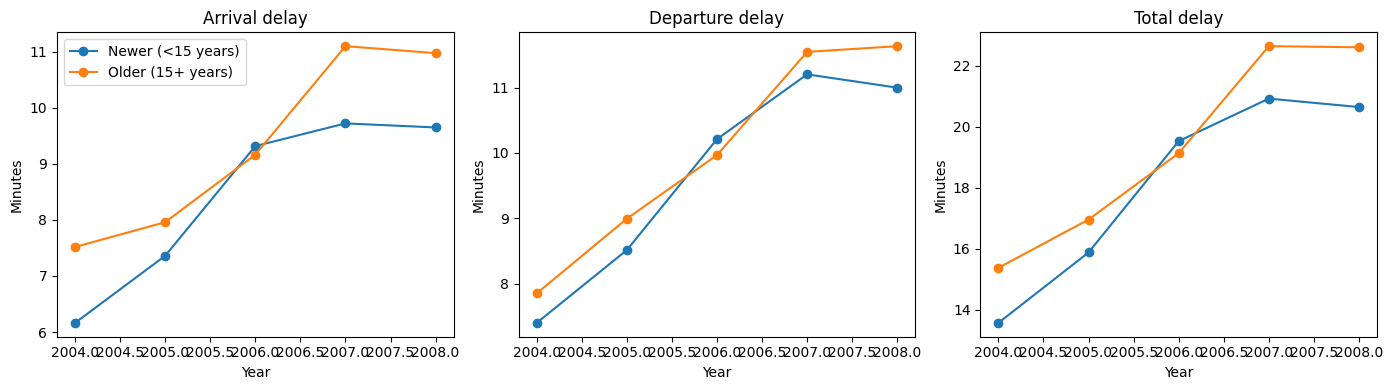

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharex=True)

for ax, metric, title in zip(
    axes,
    ["mean_arr_delay", "mean_dep_delay", "mean_total_delay"],
    ["Arrival delay", "Departure delay", "Total delay"]
):
    for grp in ["Newer (<15 years)", "Older (15+ years)"]:
        temp = age_group_summary[age_group_summary["AgeGroup"] == grp]
        ax.plot(temp["Year"], temp[metric], marker="o", label=grp)
    ax.set_title(title)
    ax.set_xlabel("Year")
    ax.set_ylabel("Minutes")

axes[0].legend()
plt.tight_layout()
plt.savefig("part2_python_2b_agegroup_multi.png", dpi=300, bbox_inches="tight")
plt.show()

In [29]:
age_delay_summary = (
    merged_b
    .groupby(["Year", "PlaneAge"], as_index=False)
    .agg(
        mean_total_delay=("TotalDelay", "mean"),
        n_flights=("TotalDelay", "size")
    )
)

# keep age values with a reasonable number of flights
age_delay_summary_filtered = age_delay_summary[age_delay_summary["n_flights"] >= 1000].copy()

print(age_delay_summary_filtered.head(20))

    Year  PlaneAge  mean_total_delay  n_flights
0   2004         0         15.587566     109140
1   2004         1         12.732443     333294
2   2004         2         13.415789     374579
3   2004         3         11.558512     476298
4   2004         4         13.085714     372435
5   2004         5         13.195600     328456
6   2004         6         13.082426     309670
7   2004         7         14.691557     146001
8   2004         8         13.892709     156854
9   2004         9         13.503876     140481
10  2004        10         14.269755     148331
11  2004        11         14.099088     115140
12  2004        12         14.935494     151692
13  2004        13         16.667372     162933
14  2004        14         16.292513     157897
15  2004        15         15.242395     147210
16  2004        16         16.670854     183788
17  2004        17         15.365975     153497
18  2004        18         16.317100      99549
19  2004        19         18.287698    

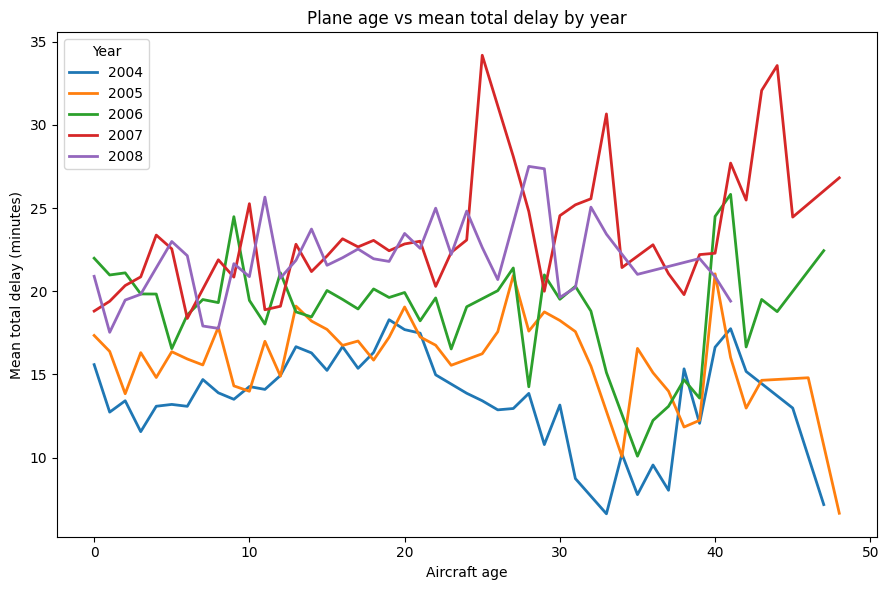

In [43]:
plt.figure(figsize=(9, 6))

for year in sorted(age_delay_summary_filtered["Year"].unique()):
    temp = age_delay_summary_filtered[age_delay_summary_filtered["Year"] == year]
    plt.plot(temp["PlaneAge"], temp["mean_total_delay"], linewidth=2, label=str(year))

plt.title("Plane age vs mean total delay by year")
plt.xlabel("Aircraft age")
plt.ylabel("Mean total delay (minutes)")
plt.legend(title="Year")
plt.tight_layout()
plt.savefig("part2_python_2b_age_trend_combined.png", dpi=300, bbox_inches="tight")
plt.show()

In [31]:
correlation_summary = (
    merged_b
    .groupby("Year")
    .apply(lambda g: pd.Series({
        "corr_age_totaldelay": g["PlaneAge"].corr(g["TotalDelay"]),
        "mean_plane_age": g["PlaneAge"].mean(),
        "mean_total_delay": g["TotalDelay"].mean(),
        "n_flights": len(g)
    }))
    .reset_index()
)

print(correlation_summary.to_string(index=False))

 Year  corr_age_totaldelay  mean_plane_age  mean_total_delay  n_flights
 2004             0.009952        8.627211         13.937814  4389789.0
 2005             0.006407        8.863724         16.109632  4921334.0
 2006            -0.006283        9.333801         19.437372  5301762.0
 2007             0.009704        9.875533         21.363705  6262849.0
 2008             0.013116       10.649986         21.182493  2055373.0


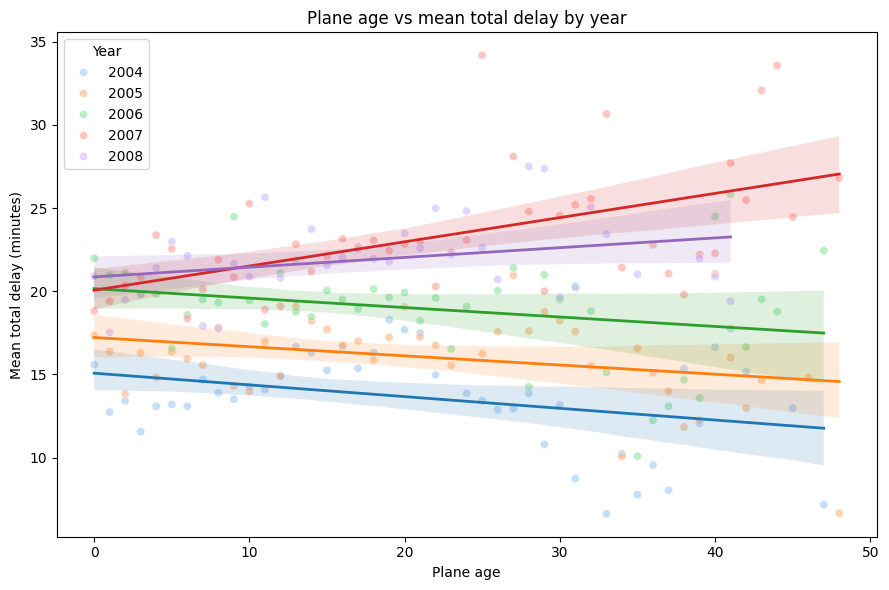

In [41]:
import seaborn as sns

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=age_delay_summary_filtered,
    x="PlaneAge",
    y="mean_total_delay",
    hue="Year",
    alpha=0.6,
    s=35,
    palette="pastel"
)

for year in sorted(age_delay_summary_filtered["Year"].unique()):
    temp = age_delay_summary_filtered[age_delay_summary_filtered["Year"] == year]
    sns.regplot(
        data=temp,
        x="PlaneAge",
        y="mean_total_delay",
        scatter=False,
        ci=95,
        line_kws={"linewidth": 2},
        label=None
    )

plt.title("Plane age vs mean total delay by year")
plt.xlabel("Plane age")
plt.ylabel("Mean total delay (minutes)")
plt.tight_layout()
plt.savefig("part2_python_2b_age_regression_overlay.png", dpi=300, bbox_inches="tight")
plt.show()

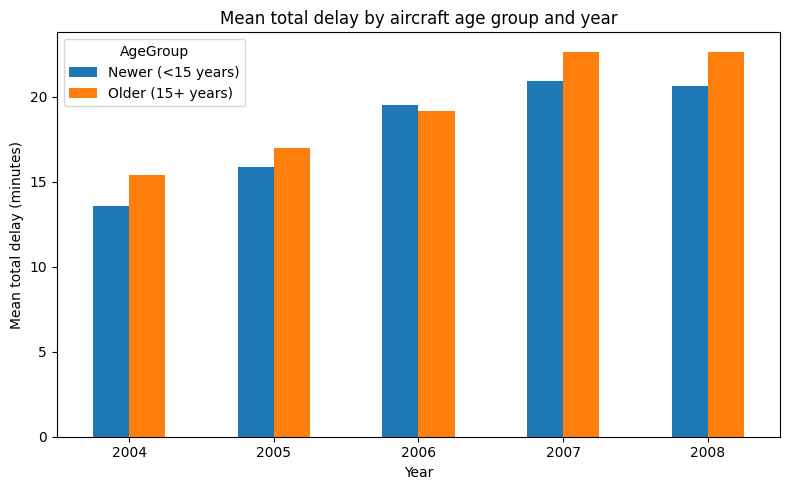

In [42]:
bar_df = age_group_summary[["Year", "AgeGroup", "mean_total_delay"]].copy()

pivot_bar = bar_df.pivot(index="Year", columns="AgeGroup", values="mean_total_delay")

pivot_bar.plot(kind="bar", figsize=(8, 5))
plt.title("Mean total delay by aircraft age group and year")
plt.xlabel("Year")
plt.ylabel("Mean total delay (minutes)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("part2_python_2b_agegroup_bar.png", dpi=300, bbox_inches="tight")
plt.show()

In [44]:
age_group_summary.to_csv("data/age_group_summary_2004_2008.csv", index=False)
age_delay_summary_filtered.to_csv("data/age_delay_summary_filtered_2004_2008.csv", index=False)
correlation_summary.to_csv("data/correlation_summary_2004_2008.csv", index=False)

In [45]:
airports = pd.read_csv("data/airports.csv")
carriers = pd.read_csv("data/carriers.csv")

print(airports.shape)
print(carriers.shape)
airports.head()

(3376, 7)
(1491, 2)


,iata,airport,city,state,country,lat,long
0,00M,Thigpen,Bay Springs,MS,USA,31.953765,-89.234505
1,00R,Livingston Municipal,Livingston,TX,USA,30.685861,-95.017928
2,00V,Meadow Lake,Colorado Springs,CO,USA,38.945749,-104.569893
3,01G,Perry-Warsaw,Perry,NY,USA,42.741347,-78.052081
4,01J,Hilliard Airpark,Hilliard,FL,USA,30.688012,-81.905944


In [46]:
airports.columns = [col.strip() for col in airports.columns]
carriers.columns = [col.strip() for col in carriers.columns]

print(airports.columns.tolist())
print(carriers.columns.tolist())

['iata', 'airport', 'city', 'state', 'country', 'lat', 'long']
['Code', 'Description']


In [47]:
flights_c = flights_raw[[
    "Year", "Month", "DayofMonth", "DayOfWeek",
    "CRSDepTime", "CRSArrTime",
    "UniqueCarrier", "Origin", "Dest",
    "Distance", "Diverted", "Cancelled"
]].copy()

flights_c = flights_c[flights_c["Cancelled"] == 0].copy()
flights_c = flights_c.dropna(subset=[
    "Year", "Month", "DayofMonth", "DayOfWeek",
    "CRSDepTime", "CRSArrTime",
    "UniqueCarrier", "Origin", "Dest",
    "Distance", "Diverted"
])

print(flights_c.shape)
flights_c.head()

(30645609, 12)


,Year,Month,DayofMonth,DayOfWeek,CRSDepTime,CRSArrTime,UniqueCarrier,Origin,Dest,Distance,Diverted,Cancelled
0,2004,1,12,1,630,915,UA,ORD,CLT,599,0,0
1,2004,1,13,2,630,915,UA,ORD,CLT,599,0,0
2,2004,1,14,3,630,915,UA,ORD,CLT,599,0,0
3,2004,1,15,4,630,915,UA,ORD,CLT,599,0,0
4,2004,1,16,5,630,915,UA,ORD,CLT,599,0,0


Part 2 (C): Final Workflow

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import statsmodels.api as sm
import seaborn as sns

In [16]:
data_dir = Path("data")

year_files = {
    2004: data_dir / "2004.csv.bz2",
    2005: data_dir / "2005.csv.bz2",
    2006: data_dir / "2006.csv.bz2",
    2007: data_dir / "2007.csv.bz2",
    2008: data_dir / "2008.csv.bz2",
}

airports = pd.read_csv("data/airports.csv")
airports.columns = [col.strip() for col in airports.columns]

origin_airports = airports[["iata", "lat", "long"]].copy().rename(columns={
    "iata": "Origin",
    "lat": "origin_lat",
    "long": "origin_long"
})

dest_airports = airports[["iata", "lat", "long"]].copy().rename(columns={
    "iata": "Dest",
    "lat": "dest_lat",
    "long": "dest_long"
})

In [17]:
def hhmm_to_hour(x):
    if pd.isna(x):
        return np.nan
    x = int(x)
    hour = x // 100
    minute = x % 100
    if hour < 0 or hour > 23 or minute < 0 or minute > 59:
        return np.nan
    return hour

In [56]:
def prepare_year_data(year):
    df = pd.read_csv(year_files[year], usecols=use_cols_c, compression="bz2")

    df = df[df["Cancelled"] == 0].copy()
    df = df.dropna(subset=[
        "Year", "Month", "DayofMonth", "DayOfWeek",
        "CRSDepTime", "CRSArrTime",
        "UniqueCarrier", "Origin", "Dest",
        "Distance", "Diverted"
    ])

    df["dep_hour"] = df["CRSDepTime"].apply(hhmm_to_hour)
    df["arr_hour"] = df["CRSArrTime"].apply(hhmm_to_hour)

    df = df.merge(origin_airports, on="Origin", how="left")
    df = df.merge(dest_airports, on="Dest", how="left")

    df = df.dropna(subset=[
        "dep_hour", "arr_hour",
        "origin_lat", "origin_long",
        "dest_lat", "dest_long"
    ]).copy()

    # Return raw data - NO dummies yet, NO carrier filter yet
    model_df = df[[
        "Diverted", "Month", "DayofMonth", "DayOfWeek",
        "dep_hour", "arr_hour", "Distance",
        "origin_lat", "origin_long", "dest_lat", "dest_long",
        "UniqueCarrier"
    ]].copy()

    return model_df

In [ ]:
def fit_year_logit(year, negative_ratio=5):
    model_df = prepare_year_data(year)

    diverted_df = model_df[model_df["Diverted"] == 1].copy()
    non_diverted_df = model_df[model_df["Diverted"] == 0].copy()

    sampled_non_diverted = non_diverted_df.sample(
        n=min(len(non_diverted_df), len(diverted_df) * negative_ratio),
        random_state=2195
    )

    fit_df = pd.concat([diverted_df, sampled_non_diverted], ignore_index=True)
    fit_df = fit_df.sample(frac=1, random_state=2195).reset_index(drop=True)

    # Filter carriers after sampling - raise threshold to 500
    carrier_counts = fit_df["UniqueCarrier"].value_counts()
    valid_carriers = carrier_counts[carrier_counts >= 500].index
    fit_df = fit_df[fit_df["UniqueCarrier"].isin(valid_carriers)].copy()

    # Remove any carrier where all sampled rows are same class (perfect separation)
    carrier_diversion_rate = fit_df.groupby("UniqueCarrier")["Diverted"].mean()
    mixed_carriers = carrier_diversion_rate[
        (carrier_diversion_rate > 0) & (carrier_diversion_rate < 1)
    ].index
    fit_df = fit_df[fit_df["UniqueCarrier"].isin(mixed_carriers)].copy()
    
    # Encode dummies after sampling and filtering
    fit_df = pd.get_dummies(fit_df, columns=["UniqueCarrier"], drop_first=True)

    X = fit_df.drop(columns=["Diverted"]).astype(float)
    y = fit_df["Diverted"].astype(int)

    X = sm.add_constant(X, has_constant="add")
    result = sm.Logit(y, X).fit(disp=False, maxiter=200)

    coef_df = pd.DataFrame({
        "feature": result.params.index,
        "coefficient": result.params.values,
        "year": year
    })
    coef_df = coef_df[coef_df["feature"] != "const"].copy()

    summary_row = {
        "year": year,
        "n_model_rows": len(model_df),
        "n_diverted_full": int((model_df["Diverted"] == 1).sum()),
        "n_not_diverted_full": int((model_df["Diverted"] == 0).sum()),
        "n_fit_rows": len(fit_df),
        "n_diverted_fit": int((fit_df["Diverted"] == 1).sum()),
        "n_not_diverted_fit": int((fit_df["Diverted"] == 0).sum()),
        "pseudo_r2": result.prsquared,
        "llf": result.llf
    }

    return coef_df, summary_row

In [59]:
all_coef_tables = []
model_summary_rows = []

for year in [2004, 2005, 2006, 2007, 2008]:
    print(f"Processing {year}...")
    coef_df, summary_row = fit_year_logit(year, negative_ratio=5)
    all_coef_tables.append(coef_df)
    model_summary_rows.append(summary_row)
    print(f"{year} done.")

Processing 2004...
2004 done.
Processing 2005...
2005 done.
Processing 2006...
2006 done.
Processing 2007...
2007 done.
Processing 2008...
2008 done.


In [60]:
coef_all_years = pd.concat(all_coef_tables, ignore_index=True)
model_summary = pd.DataFrame(model_summary_rows)

print(model_summary.to_string(index=False))

 year  n_model_rows  n_diverted_full  n_not_diverted_full  n_fit_rows  n_diverted_fit  n_not_diverted_fit  pseudo_r2           llf
 2004       7001508            13784              6987724       82217           13764               68453   0.026929 -36141.881331
 2005       7006866            14028              6992838       83200           14011               69189   0.030801 -36556.328990
 2006       7019988            16186              7003802       96489           16161               80328   0.050655 -41393.281881
 2007       7291741            16453              7275288       95839           16453               79386   0.043141 -42049.186261
 2008       2324501             5380              2319121       31597            5340               26257   0.043919 -13724.157621


In [61]:
coef_all_years.to_csv("data/coef_all_years_2004_2008.csv", index=False)
model_summary.to_csv("data/model_summary_2004_2008.csv", index=False)

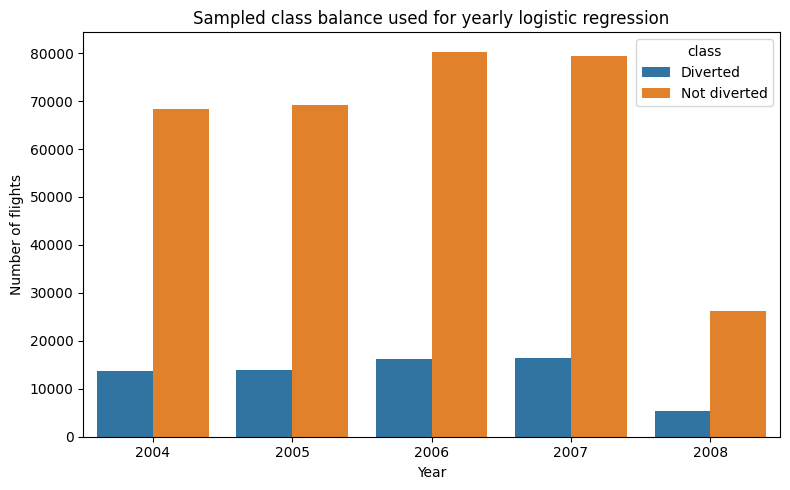

In [62]:
balance_plot_df = model_summary[[
    "year", "n_diverted_fit", "n_not_diverted_fit"
]].copy()

balance_plot_df = balance_plot_df.melt(
    id_vars="year",
    value_vars=["n_diverted_fit", "n_not_diverted_fit"],
    var_name="class",
    value_name="count"
)

balance_plot_df["class"] = balance_plot_df["class"].replace({
    "n_diverted_fit": "Diverted",
    "n_not_diverted_fit": "Not diverted"
})

plt.figure(figsize=(8, 5))
sns.barplot(data=balance_plot_df, x="year", y="count", hue="class")
plt.title("Sampled class balance used for yearly logistic regression")
plt.xlabel("Year")
plt.ylabel("Number of flights")
plt.tight_layout()
plt.savefig("part2_python_2c_class_balance.png", dpi=300, bbox_inches="tight")
plt.show()

In [63]:
top_features = (
    coef_all_years
    .assign(abs_coef=lambda d: d["coefficient"].abs())
    .groupby("feature", as_index=False)["abs_coef"]
    .mean()
    .sort_values("abs_coef", ascending=False)
    .head(12)["feature"]
    .tolist()
)

coef_heatmap_df = coef_all_years[coef_all_years["feature"].isin(top_features)].copy()
coef_heatmap = coef_heatmap_df.pivot(index="feature", columns="year", values="coefficient")

coef_heatmap

year,2004,2005,2006,2007,2008
feature,,,,,
UniqueCarrier_AA,NaN,NaN,NaN,NaN,2.705380
UniqueCarrier_AQ,NaN,NaN,NaN,-1.439777,NaN
UniqueCarrier_AS,0.531781,0.511824,0.520465,0.372236,3.002655
UniqueCarrier_B6,-0.409106,0.038470,0.327110,-0.246615,2.442613
UniqueCarrier_F9,NaN,-0.573237,-0.827863,-0.826864,NaN
UniqueCarrier_HA,NaN,NaN,-2.304090,-4.073860,NaN
UniqueCarrier_MQ,0.219411,0.083119,0.396471,0.291998,3.014222
UniqueCarrier_OO,0.328394,0.156425,-0.173630,-0.271369,2.998665
UniqueCarrier_TZ,-1.913362,NaN,NaN,NaN,NaN


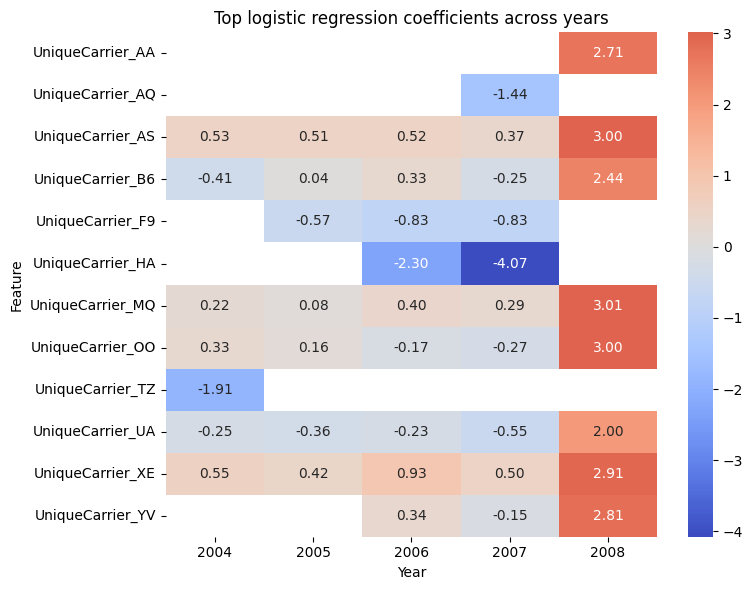

In [64]:
plt.figure(figsize=(8, 6))
sns.heatmap(coef_heatmap, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Top logistic regression coefficients across years")
plt.xlabel("Year")
plt.ylabel("Feature")
plt.tight_layout()
plt.savefig("part2_python_2c_coefficients_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

In [65]:
top_coef_table = (
    coef_all_years
    .assign(abs_coef=lambda d: d["coefficient"].abs())
    .sort_values(["year", "abs_coef"], ascending=[True, False])
)

top_coef_table.head(25)

,feature,coefficient,year,abs_coef
22,UniqueCarrier_TZ,-1.913362,2004,1.913362
26,UniqueCarrier_XE,0.550893,2004,0.550893
10,UniqueCarrier_AS,0.531781,2004,0.531781
17,UniqueCarrier_HP,-0.419192,2004,0.419192
11,UniqueCarrier_B6,-0.409106,2004,0.409106
21,UniqueCarrier_OO,0.328394,2004,0.328394
23,UniqueCarrier_UA,-0.252560,2004,0.252560
18,UniqueCarrier_MQ,0.219411,2004,0.219411
20,UniqueCarrier_OH,0.207648,2004,0.207648
13,UniqueCarrier_DH,0.199203,2004,0.199203


In [66]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve, roc_auc_score

In [71]:
def fit_year_logit_with_roc(year, negative_ratio=5, test_size=0.3):
    model_df = prepare_year_data(year)
    diverted_df = model_df[model_df["Diverted"] == 1].copy()
    non_diverted_df = model_df[model_df["Diverted"] == 0].copy()
    sampled_non_diverted = non_diverted_df.sample(
        n=min(len(non_diverted_df), len(diverted_df) * negative_ratio),
        random_state=2195
    )
    fit_df = pd.concat([diverted_df, sampled_non_diverted], ignore_index=True)
    fit_df = fit_df.sample(frac=1, random_state=2195).reset_index(drop=True)

    # Filter carriers AFTER sampling - raise threshold to 500
    carrier_counts = fit_df["UniqueCarrier"].value_counts()
    valid_carriers = carrier_counts[carrier_counts >= 500].index
    fit_df = fit_df[fit_df["UniqueCarrier"].isin(valid_carriers)].copy()

    # Also remove any carrier where all sampled rows are same class (perfect separation)
    carrier_diversion_rate = fit_df.groupby("UniqueCarrier")["Diverted"].mean()
    mixed_carriers = carrier_diversion_rate[
        (carrier_diversion_rate > 0) & (carrier_diversion_rate < 1)
    ].index
    fit_df = fit_df[fit_df["UniqueCarrier"].isin(mixed_carriers)].copy()

    # Encode dummies AFTER sampling and filtering
    fit_df = pd.get_dummies(fit_df, columns=["UniqueCarrier"], drop_first=True)

    X = fit_df.drop(columns=["Diverted"]).astype(float)
    y = fit_df["Diverted"].astype(int)
    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=test_size,
        random_state=2195,
        stratify=y
    )
    X_train = sm.add_constant(X_train, has_constant="add")
    X_test = sm.add_constant(X_test, has_constant="add")
    result = sm.Logit(y_train, X_train).fit(disp=False, maxiter=200)
    y_score = result.predict(X_test)
    fpr, tpr, _ = roc_curve(y_test, y_score)
    auc_value = roc_auc_score(y_test, y_score)
    return {
        "year": year,
        "fpr": fpr,
        "tpr": tpr,
        "auc": auc_value,
        "n_train": len(X_train),
        "n_test": len(X_test),
        "n_diverted_test": int(y_test.sum()),
        "n_not_diverted_test": int((y_test == 0).sum())
    }

In [72]:
roc_results = []

for year in [2004, 2005, 2006, 2007, 2008]:
    print(f"Running ROC workflow for {year}...")
    roc_info = fit_year_logit_with_roc(year, negative_ratio=5, test_size=0.3)
    roc_results.append(roc_info)
    print(f"{year} done. AUC = {roc_info['auc']:.4f}")

Running ROC workflow for 2004...
2004 done. AUC = 0.6245
Running ROC workflow for 2005...
2005 done. AUC = 0.6303
Running ROC workflow for 2006...
2006 done. AUC = 0.6603
Running ROC workflow for 2007...
2007 done. AUC = 0.6506
Running ROC workflow for 2008...
2008 done. AUC = 0.6424


In [73]:
roc_summary = pd.DataFrame([
    {
        "year": r["year"],
        "auc": r["auc"],
        "n_train": r["n_train"],
        "n_test": r["n_test"],
        "n_diverted_test": r["n_diverted_test"],
        "n_not_diverted_test": r["n_not_diverted_test"]
    }
    for r in roc_results
])

print(roc_summary.to_string(index=False))

 year      auc  n_train  n_test  n_diverted_test  n_not_diverted_test
 2004 0.624547    57551   24666             4129                20537
 2005 0.630316    58240   24960             4203                20757
 2006 0.660283    67542   28947             4848                24099
 2007 0.650620    67087   28752             4936                23816
 2008 0.642443    22117    9480             1602                 7878


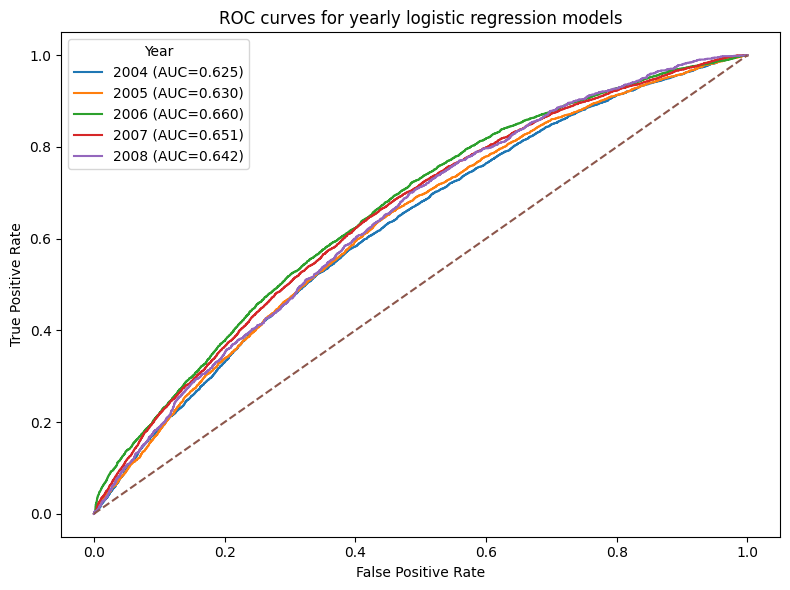

In [74]:
plt.figure(figsize=(8, 6))

for r in roc_results:
    plt.plot(r["fpr"], r["tpr"], label=f"{r['year']} (AUC={r['auc']:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--")
plt.title("ROC curves for yearly logistic regression models")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(title="Year")
plt.tight_layout()
plt.savefig("part2_python_2c_roc_curves.png", dpi=300, bbox_inches="tight")
plt.show()

In [75]:
roc_summary.to_csv("data/roc_summary_2004_2008.csv", index=False)

In [76]:
roc_points = pd.concat([
    pd.DataFrame({
        "year": r["year"],
        "fpr": r["fpr"],
        "tpr": r["tpr"]
    })
    for r in roc_results
], ignore_index=True)

roc_points.to_csv("data/roc_points_2004_2008.csv", index=False)